# **torch.autograd**를 이용한 자동미분


신경망 학습에서 핵심은 결국 loss를 줄이는 방향으로 weight와 bias를 바꾸는 것이다.
-  그러려면 loss를 각 파라미터(weight, 가중치)에 대해 **backpropagation** 을 통해 미분해야 한다.
- PyTorch의 autograd (auto - gradient)는 그 미분을 자동으로 계산해줍니다.


In [1]:
import torch

x = torch.ones(5)   # 입력 데이터
y = torch.zeros(3)  # 출력 데이터

print(x)
print(y)

tensor([1., 1., 1., 1., 1.])
tensor([0., 0., 0.])


## **autograd 활용법 (sigmoid, BCE)**

**1. requires_grad = True 옵션**
- 나중에 미분해야 하니까 계산에 이용되는 과정 기억해두라는 의미이다.

```
w = torch.randn(5, 3, requires_grad=True)
```

이미 텐서가 생성된 이후에도 옵션을 추가할 수 있다.

```
w.requires_grad_(True)
```

**2. Sigmoid**

```
p = torch.sigmoid(z)
```

**3. Binary Cross Entropy**

```
loss = torch.nn.functional.binary_cross_entropy(p, y)
```


In [8]:
w = torch.randn(5, 3, requires_grad=True)                         # 가중치: 입력 5 → 출력 3
b = torch.randn(3, requires_grad=True)                            # 편향: 출력 3개에 하나씩

In [12]:
z = x @ w + b                                                     # 선형 변환: z = xW + b  → shape (3,)
p = torch.sigmoid(z)
loss = torch.nn.functional.binary_cross_entropy(p, y)
print(loss)

tensor(3.5260, grad_fn=<BinaryCrossEntropyBackward0>)



Sigmoid -> Binary Cross Entropy를 순차적으로 한 번에 처리하는 명령어도 지원한다.
```
loss = torch.nn.functional.binary_cross_entropy_with_logits(z, y)
```


In [10]:
z = x @ w + b                                                     # 선형 변환: z = xW + b  → shape (3,)
loss = torch.nn.functional.binary_cross_entropy_with_logits(z, y)
print(loss)

tensor(3.5260, grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)


위 코드는 아래와 같은 그래프를 만들게 된다.

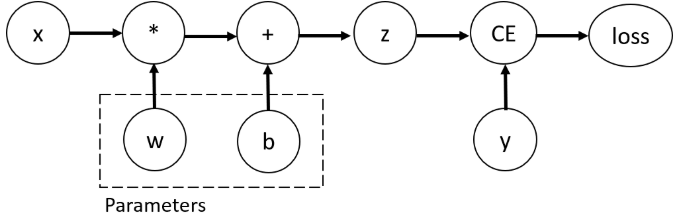

이 네트워크에서 `w`와 `b`는 최적화해야 할 매개변수 이다.
- 이 변수들에 대한 손실 함수의 기울기를 계산할 수 있어야 한다.
- 이를 위해 해당 텐서의 `requires_grad` 속성을 설정해준다.

`grad_fn`은 이 **Tensor가 어떤 계산을 통해 만들어졌는지** 가리키는 정보이다.


In [13]:
print(f"Gradient function for z = {z.grad_fn}")
print(f"Gradient function for loss = {loss.grad_fn}")

Gradient function for z = <AddBackward0 object at 0x7e8e107b9ba0>
Gradient function for loss = <BinaryCrossEntropyBackward0 object at 0x7e8e107b86d0>


## **Gradient 계산하기**

loss에서 출발해서 계산그래프를 거꾸로 따라가면서 각 parameter의 gradient 계산한다.

계산 그래프에서 `requires_grad=True`로 설정된 leaf node(리프 노드)에 대해서만 `.grad` 값을 직접 얻을 수 있다.
* PyTorch는 기본적으로 우리가 직접 만든 학습 대상 Tensor의 .grad만 보관하고, 계산 중간에 생긴 Tensor들의 .grad는 보관하지 않는다.

하나의 계산 그래프에서는 기본적으로 backward()를 한 번만 실행할 수 있다.

* PyTorch가 미분 계산에 사용했던 계산 그래프의 중간 정보들을 메모리를 아끼기 위해 버리기 때문이다.

In [14]:
loss.backward()

In [15]:
print(w.grad)
print(b.grad)

tensor([[0.3148, 0.3248, 0.3274],
        [0.3148, 0.3248, 0.3274],
        [0.3148, 0.3248, 0.3274],
        [0.3148, 0.3248, 0.3274],
        [0.3148, 0.3248, 0.3274]])
tensor([0.3148, 0.3248, 0.3274])
